# ClaimGuard: Vehicle Insurance Claim Fraud Detection
### CSL236 end-term project · EDA, preprocessing and model comparison notebook

| | |
|---|---|
| **Team members (roll numbers)** | Krishna Bakshi (24CSU297), Naman Sharma (24CSU287) |
| **Section** | *fill in* |
| **Dataset** | *Vehicle Insurance Claim Fraud Detection* (`fraud_oracle.csv`), Oracle sample data published on Kaggle by Shivam Bansal: https://www.kaggle.com/datasets/shivamb/vehicle-claim-fraud-detection |

**Problem.** Insurers lose money to staged or exaggerated claims, but checking every claim by hand is too slow. Given a claim's details (policy, vehicle, driver, accident), we predict whether it is **fraudulent (1) or genuine (0)**, so investigators can look at the riskiest claims first.

This notebook covers the data work behind the system: loading and cleaning, EDA, preprocessing with the reasons for each choice, and a comparison of three algorithms. `train.py` then runs the same preprocessing (shared through `features.py`) with MLflow tracking, and `app.py` serves the chosen model.

In [1]:
import sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
sys.path.insert(0, "..")
from features import load_clean, build_preprocessor, FEATURES, TARGET, ORDINAL, BINARY, NOMINAL, NUMERIC
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score, recall_score,
                             precision_recall_curve, ConfusionMatrixDisplay, RocCurveDisplay)
from sklearn.inspection import permutation_importance

pd.set_option("display.max_columns", 50); pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
FIG = Path("../docs/figures"); FIG.mkdir(parents=True, exist_ok=True)
SEED = 42

## 1. Load and inspect the raw data

In [2]:
raw = pd.read_csv("../data/fraud_oracle.csv", encoding="utf-8-sig")
print("Shape:", raw.shape)
raw.head()

Shape: (15420, 36)


,Month,WeekOfMonth,DayOfWeek,Make,AccidentArea,DayOfWeekClaimed,MonthClaimed,WeekOfMonthClaimed,Sex,MaritalStatus,Age,Fault,PolicyType,VehicleCategory,VehiclePrice,FraudFound_P,PolicyNumber,RepNumber,Deductible,DriverRating,Days_Policy_Accident,Days_Policy_Claim,PastNumberOfClaims,AgeOfVehicle,AgeOfPolicyHolder,PoliceReportFiled,WitnessPresent,AgentType,NumberOfSuppliments,AddressChange_Claim,NumberOfCars,Year,BasePolicy,Unnamed: 33,Unnamed: 34,Statement
0,Dec,5,Wednesday,Honda,Urban,Tuesday,Jan,1,Female,Single,21,Policy Holder,Sport - Liability,Sport,more than 69000,0,1,12,300,1,more than 30,more than 30,none,3 years,26 to 30,No,No,External,none,1 year,3 to 4,1994,Liability,-,Sport - Liability,True
1,Jan,3,Wednesday,Honda,Urban,Monday,Jan,4,Male,Single,34,Policy Holder,Sport - Collision,Sport,more than 69000,0,2,15,400,4,more than 30,more than 30,none,6 years,31 to 35,Yes,No,External,none,no change,1 vehicle,1994,Collision,-,Sport - Collision,True
2,Oct,5,Friday,Honda,Urban,Thursday,Nov,2,Male,Married,47,Policy Holder,Sport - Collision,Sport,more than 69000,0,3,7,400,3,more than 30,more than 30,1,7 years,41 to 50,No,No,External,none,no change,1 vehicle,1994,Collision,-,Sport - Collision,True
3,Jun,2,Saturday,Toyota,Rural,Friday,Jul,1,Male,Married,65,Third Party,Sedan - Liability,Sport,20000 to 29000,0,4,4,400,2,more than 30,more than 30,1,more than 7,51 to 65,Yes,No,External,more than 5,no change,1 vehicle,1994,Liability,-,Sport - Liability,False
4,Jan,5,Monday,Honda,Urban,Tuesday,Feb,2,Female,Single,27,Third Party,Sport - Collision,Sport,more than 69000,0,5,3,400,1,more than 30,more than 30,none,5 years,31 to 35,No,No,External,none,no change,1 vehicle,1994,Collision,-,Sport - Collision,True


In [3]:
print(raw.dtypes.value_counts(), "\n")
num_cols = raw.select_dtypes("number").columns.tolist()
cat_cols = raw.select_dtypes(exclude="number").columns.tolist()
print(f"Numeric ({len(num_cols)}):", num_cols)
print(f"Text / categorical ({len(cat_cols)}):", cat_cols)

object    26
int64      9
bool       1
Name: count, dtype: int64 

Numeric (9): ['WeekOfMonth', 'WeekOfMonthClaimed', 'Age', 'FraudFound_P', 'PolicyNumber', 'RepNumber', 'Deductible', 'DriverRating', 'Year']
Text / categorical (27): ['Month', 'DayOfWeek', 'Make', 'AccidentArea', 'DayOfWeekClaimed', 'MonthClaimed', 'Sex', 'MaritalStatus', 'Fault', 'PolicyType', 'VehicleCategory', 'VehiclePrice', 'Days_Policy_Accident', 'Days_Policy_Claim', 'PastNumberOfClaims', 'AgeOfVehicle', 'AgeOfPolicyHolder', 'PoliceReportFiled', 'WitnessPresent', 'AgentType', 'NumberOfSuppliments', 'AddressChange_Claim', 'NumberOfCars', 'BasePolicy', 'Unnamed: 33', 'Unnamed: 34', 'Statement']


In [4]:
raw[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
WeekOfMonth,15420.0,2.788586,1.287585,1.0,2.00,3.0,4.00,5.0
WeekOfMonthClaimed,15420.0,2.693969,1.259115,1.0,2.00,3.0,4.00,5.0
Age,15420.0,39.855707,13.492377,0.0,31.00,38.0,48.00,80.0
FraudFound_P,15420.0,0.059857,0.237230,0.0,0.00,0.0,0.00,1.0
PolicyNumber,15420.0,7710.500000,4451.514911,1.0,3855.75,7710.5,11565.25,15420.0
RepNumber,15420.0,8.483268,4.599948,1.0,5.00,8.0,12.00,16.0
Deductible,15420.0,407.704280,43.950998,300.0,400.00,400.0,400.00,700.0
DriverRating,15420.0,2.487808,1.119453,1.0,1.00,2.0,3.00,4.0
Year,15420.0,1994.866472,0.803313,1994.0,1994.00,1995.0,1996.00,1996.0


### 1.1 Hidden data-quality problems

`raw.isna().sum()` reports **no** missing values, but looking at the values shows three problems:

In [5]:
print("NaN cells:", raw.isna().sum().sum())
print("Rows with Age == 0:", (raw.Age == 0).sum(), "-> all in AgeOfPolicyHolder band:", raw.loc[raw.Age == 0, "AgeOfPolicyHolder"].unique())
print("Rows with claim day/month == '0':", ((raw.DayOfWeekClaimed == "0") | (raw.MonthClaimed == "0")).sum())
print("Extra columns not in the original Kaggle file:", raw.columns[33:].tolist())
print("Misspelt car makes:", sorted(set(raw.Make) & {"Accura", "Nisson", "Mecedes", "Porche"}))

NaN cells: 0
Rows with Age == 0: 320 -> all in AgeOfPolicyHolder band: ['16 to 17']
Rows with claim day/month == '0': 1
Extra columns not in the original Kaggle file: ['Unnamed: 33', 'Unnamed: 34', 'Statement']
Misspelt car makes: ['Accura', 'Mecedes', 'Nisson', 'Porche']


| Problem | Decision | Why |
|---|---|---|
| `Age == 0` in 320 rows | Treat as **missing**: set to NaN, then impute with the training median and add an `age_missing` flag (Section 3) | Nobody driving is 0 years old, so it's a placeholder. Dropping 320 rows would lose about 30 fraud cases, and fraud is the class we're short of. |
| `DayOfWeekClaimed`/`MonthClaimed == '0'` in 1 row | **Drop the row** | Without a claim date we can't compute the claim delay, and it's a single row out of 15,420. |
| 3 extra columns (`Unnamed: 33`, `Unnamed: 34`, `Statement`) | **Drop** | They are not in the original dataset (it has 33 columns) and came from the copy we downloaded. Their meaning is undocumented, and `Statement` mirrors `BasePolicy`, so it could leak information. |
| Car-make typos | **Fix spelling**; group makes with < 0.5% of rows into **"Other"** | Typos would create duplicate categories, and very rare makes give one-hot columns too few examples to learn from. |

These steps are **stateless** (nothing is computed from the data), so they can safely run before the train/test split. They live in `features.load_clean()`, which `train.py` uses as well.

## 2. Exploratory data analysis

Clean shape: (15419, 22)


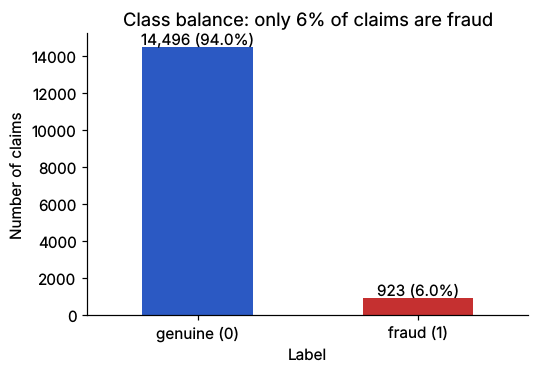

In [6]:
df = load_clean("../data/fraud_oracle.csv")
print("Clean shape:", df.shape)
counts = df[TARGET].value_counts()
ax = counts.rename({0: "genuine (0)", 1: "fraud (1)"}).plot.bar(color=["#2b59c3", "#c53030"], rot=0, figsize=(5, 3.5))
ax.set_title("Class balance: only 6% of claims are fraud"); ax.set_ylabel("Number of claims"); ax.set_xlabel("Label")
for i, v in enumerate(counts): ax.text(i, v, f"{v:,} ({v/len(df):.1%})", ha="center", va="bottom")
plt.tight_layout(); plt.savefig(FIG / "class_balance.png", dpi=150); plt.show()

**Key insight 1: strong imbalance.** A model that always says "genuine" would be 94% accurate and useless. So we do **not** use accuracy. We use **ROC-AUC**, **PR-AUC** (average precision; a random model scores 0.06 here), **recall** (share of frauds caught) and **F1**. We also use `class_weight="balanced"` and tune the decision threshold.

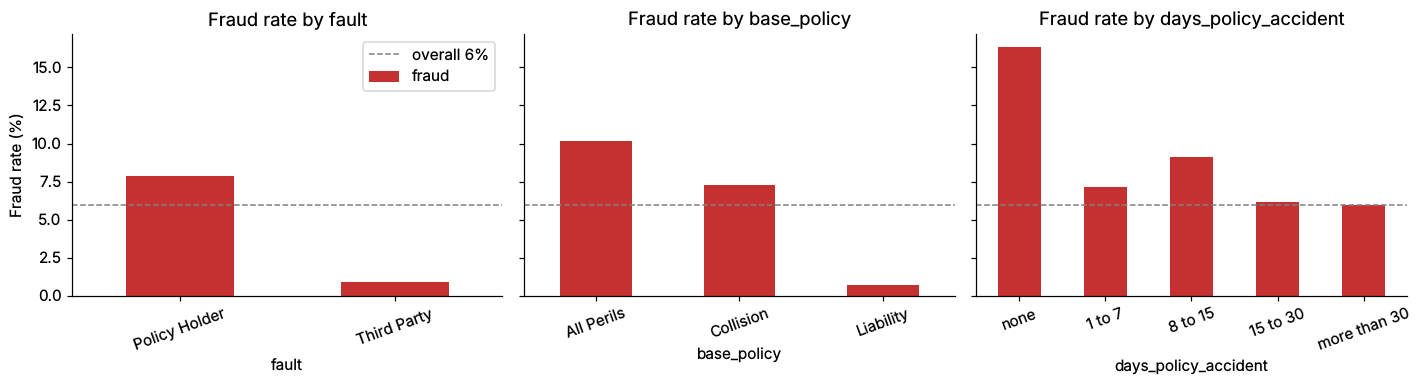

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, col in zip(axes, ["fault", "base_policy", "days_policy_accident"]):
    order = ORDINAL.get(col) or sorted(df[col].unique())
    rate = df.groupby(col)[TARGET].mean().reindex(order) * 100
    rate.plot.bar(ax=ax, color="#c53030", rot=20)
    ax.axhline(df[TARGET].mean() * 100, ls="--", c="grey", lw=1, label="overall 6%")
    ax.set_title(f"Fraud rate by {col}"); ax.set_xlabel(col); ax.set_ylabel("Fraud rate (%)")
axes[0].legend()
plt.tight_layout(); plt.savefig(FIG / "fraud_rate_by_category.png", dpi=150); plt.show()

**Key insight 2.** When the **policy holder is at fault**, the fraud rate is about 8%, against about 1% when a third party is. On **liability-only** policies, which don't pay for the holder's own car, fraud almost disappears (0.7%), because there is nothing to gain. Accidents that happen in the **first days of a policy** are far riskier, which is a classic "buy cover after the crash" pattern.

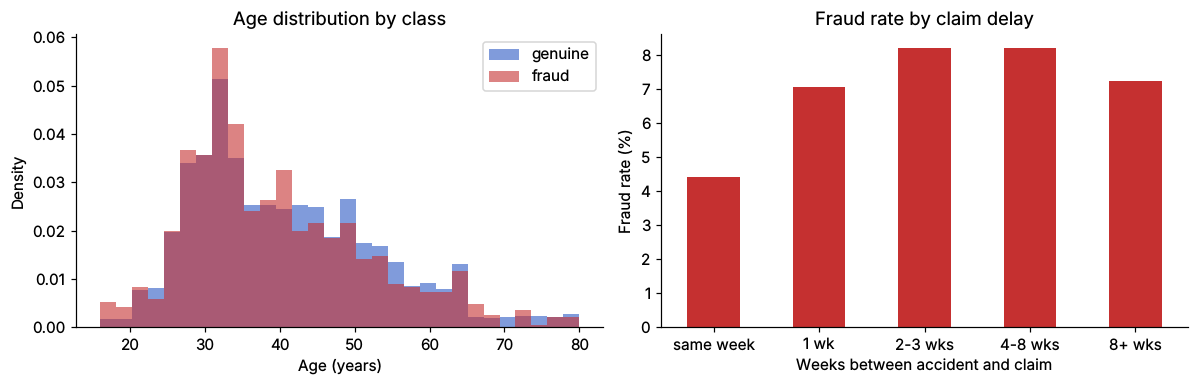

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for lbl, c in [(0, "#2b59c3"), (1, "#c53030")]:
    axes[0].hist(df.loc[df[TARGET] == lbl, "age"].dropna(), bins=30, alpha=.6, density=True, color=c, label=["genuine", "fraud"][lbl])
axes[0].set_title("Age distribution by class"); axes[0].set_xlabel("Age (years)"); axes[0].set_ylabel("Density"); axes[0].legend()
rate = df.groupby(pd.cut(df.claim_delay_weeks, [-1, 0, 1, 3, 8, 52], labels=["same week", "1 wk", "2-3 wks", "4-8 wks", "8+ wks"]), observed=True)[TARGET].mean() * 100
rate.plot.bar(ax=axes[1], color="#c53030", rot=0)
axes[1].set_title("Fraud rate by claim delay"); axes[1].set_xlabel("Weeks between accident and claim"); axes[1].set_ylabel("Fraud rate (%)")
plt.tight_layout(); plt.savefig(FIG / "age_and_delay.png", dpi=150); plt.show()

**Key insight 3.** Claims filed in the **same week** as the accident are the safest. Delays of a week or more raise the fraud rate. `claim_delay_weeks` is a feature **we engineered** from the accident and claim month and week-of-month columns, because the raw dataset only gives calendar positions. Age matters less: young drivers are slightly riskier.

## 3. Train/test split, done first

Everything after this point **learns** from data: medians, category lists, means and standard deviations. To avoid data leakage, we split now and fit every step on the **training set only**. The split is stratified (80/20, fixed seed), so both sets keep the 6% fraud rate.

In [9]:
X, y = df[FEATURES], df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print("Train:", X_train.shape, f"fraud {y_train.mean():.2%}", "| Test:", X_test.shape, f"fraud {y_test.mean():.2%}")

Train: (12335, 21) fraud 5.98% | Test: (3084, 21) fraud 6.00%


## 4. Preprocessing decisions

### 4.1 Feature selection: from 33 raw columns to 21 features

| Dropped column(s) | Reason |
|---|---|
| `PolicyNumber` | A unique ID with no predictive meaning. A model could memorise it, which would be overfitting. |
| `RepNumber` | The ID of the claims representative (16 values). It describes the insurer's process, not the claim, and would not generalise. |
| `PolicyType` | Exactly `VehicleCategory` + `BasePolicy` combined, so it's redundant. |
| `AgeOfPolicyHolder` | A banded copy of `Age` (we checked the crosstab: each age falls in one band). Keeping both would double-count. |
| `Days_Policy_Claim` | Near-constant: 99.5% of rows are "more than 30". |
| `Year` | 1994–1996 only. A future claim will never be from those years, so learning year effects would not generalise. |
| `Month`, `WeekOfMonth`, `DayOfWeek`, `MonthClaimed`, `WeekOfMonthClaimed`, `DayOfWeekClaimed` | Calendar position on its own isn't a fraud signal. We **replace** these six columns with one engineered feature, `claim_delay_weeks`. |

That leaves **21 model features**. Section 6 checks with permutation importance that the kept features carry signal.

In [10]:
print(f"Raw columns: {raw.shape[1]} (33 original + 3 extra)  ->  model features: {len(FEATURES)}")
pd.DataFrame({"type": ["numeric"] * len(NUMERIC) + ["binary"] * len(BINARY) + ["ordinal"] * len(ORDINAL) + ["nominal"] * len(NOMINAL)},
             index=FEATURES).T

Raw columns: 36 (33 original + 3 extra)  ->  model features: 21


,age,deductible,driver_rating,claim_delay_weeks,sex,fault,accident_area,police_report_filed,witness_present,agent_type,vehicle_price,age_of_vehicle,past_number_of_claims,number_of_supplements,address_change_claim,number_of_cars,days_policy_accident,marital_status,base_policy,vehicle_category,make
type,numeric,numeric,numeric,numeric,binary,binary,binary,binary,binary,binary,ordinal,ordinal,ordinal,ordinal,ordinal,ordinal,ordinal,nominal,nominal,nominal,nominal


### 4.2 Missing values
Only `age` has missing values (the 0 placeholders, now NaN).

**Decision: median imputation plus a missing-indicator flag** (`SimpleImputer(strategy="median", add_indicator=True)`).
* **Median rather than mean:** age is slightly right-skewed, and the median is not pulled by the over-65 drivers.
* **Group-wise imputation was considered:** filling from the `AgeOfPolicyHolder` band. But every missing row is in the "16 to 17" band, and *no* row in that band has a real age, so there is nothing to compute a group value from.
* **The indicator flag** keeps the fact that age was unknown, in case that pattern is itself informative.

In [11]:
from sklearn.impute import SimpleImputer
imp = SimpleImputer(strategy="median", add_indicator=True).fit(X_train[["age"]])
print("Training median age used for imputation:", imp.statistics_[0])
print("Missing ages  train:", X_train.age.isna().sum(), " test:", X_test.age.isna().sum())

Training median age used for imputation: 39.0
Missing ages  train: 256  test: 63


### 4.3 Encoding categorical columns

| Type | Columns | Encoding | Why |
|---|---|---|---|
| **Binary** | sex, fault, accident_area, police_report_filed, witness_present, agent_type | 0/1 (`OrdinalEncoder` with fixed order, for example Third Party=0, Policy Holder=1) | Two values only need one column. |
| **Ordinal** | vehicle_price, age_of_vehicle, past_number_of_claims, number_of_supplements, address_change_claim, number_of_cars, days_policy_accident | Integers in the **explicit order** below | These are ranges with a natural order. Integers keep "more than 69000 > 60000 to 69000" and use one column each. |
| **Nominal** | marital_status, base_policy, vehicle_category, make | **One-hot** (`handle_unknown="ignore"`) | No order exists ("Honda" is not greater than "Ford"). A single integer code would invent one. |

In [12]:
for col, order in ORDINAL.items():
    print(f"{col:<24}", "  <  ".join(f"{v} ({i})" for i, v in enumerate(order)))

vehicle_price            less than 20000 (0)  <  20000 to 29000 (1)  <  30000 to 39000 (2)  <  40000 to 59000 (3)  <  60000 to 69000 (4)  <  more than 69000 (5)
age_of_vehicle           new (0)  <  2 years (1)  <  3 years (2)  <  4 years (3)  <  5 years (4)  <  6 years (5)  <  7 years (6)  <  more than 7 (7)
past_number_of_claims    none (0)  <  1 (1)  <  2 to 4 (2)  <  more than 4 (3)
number_of_supplements    none (0)  <  1 to 2 (1)  <  3 to 5 (2)  <  more than 5 (3)
address_change_claim     no change (0)  <  under 6 months (1)  <  1 year (2)  <  2 to 3 years (3)  <  4 to 8 years (4)
number_of_cars           1 vehicle (0)  <  2 vehicles (1)  <  3 to 4 (2)  <  5 to 8 (3)  <  more than 8 (4)
days_policy_accident     none (0)  <  1 to 7 (1)  <  8 to 15 (2)  <  15 to 30 (3)  <  more than 30 (4)


### 4.4 Binning
The dataset is **already heavily binned**: vehicle price, vehicle age, past claims and days from policy start to accident all arrive as ranges, so there are no raw values left to re-bin. We tried binning the one continuous column, `age`, into the same bands as `AgeOfPolicyHolder`, and also binning `claim_delay_weeks`, which is used for the EDA chart above. The cross-validated scores below are practically identical (continuous age is very slightly better), because tree models learn their own cut points anyway. Binning would only throw away detail, so we keep `age` and `claim_delay_weeks` continuous in the final model.

In [13]:
def cv_auc(Xtr):
    pipe = HistGradientBoostingClassifier(class_weight="balanced", learning_rate=0.05, max_depth=6, random_state=SEED)
    Xn = pd.get_dummies(Xtr, dtype=float)
    return cross_validate(pipe, Xn, y_train, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring="roc_auc")["test_score"].mean()

binned = X_train.copy()
binned["age"] = pd.cut(binned.age.fillna(binned.age.median()), [0, 20, 25, 30, 35, 40, 50, 65, 120]).astype(str)
print(f"CV ROC-AUC with continuous age: {cv_auc(X_train):.4f}")
print(f"CV ROC-AUC with binned age:     {cv_auc(binned):.4f}")

CV ROC-AUC with continuous age: 0.8125


CV ROC-AUC with binned age:     0.8117


### 4.5 Outliers (IQR rule)

In [14]:
rows = []
for col in NUMERIC:
    s = X_train[col].dropna(); q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    rows.append({"feature": col, "Q1": q1, "Q3": q3, "lower": lo, "upper": hi, "min": s.min(), "max": s.max(),
                 "outliers": int(((s < lo) | (s > hi)).sum()), "outlier %": round(((s < lo) | (s > hi)).mean() * 100, 1)})
pd.DataFrame(rows).set_index("feature")

,Q1,Q3,lower,upper,min,max,outliers,outlier %
feature,,,,,,,,
age,31.0,49.0,4.0,76.0,16.0,80.0,91,0.8
deductible,400.0,400.0,400.0,400.0,300.0,700.0,449,3.6
driver_rating,1.0,3.0,-2.0,6.0,1.0,4.0,0,0.0
claim_delay_weeks,0.0,1.0,-1.5,2.5,0.0,48.0,1554,12.6


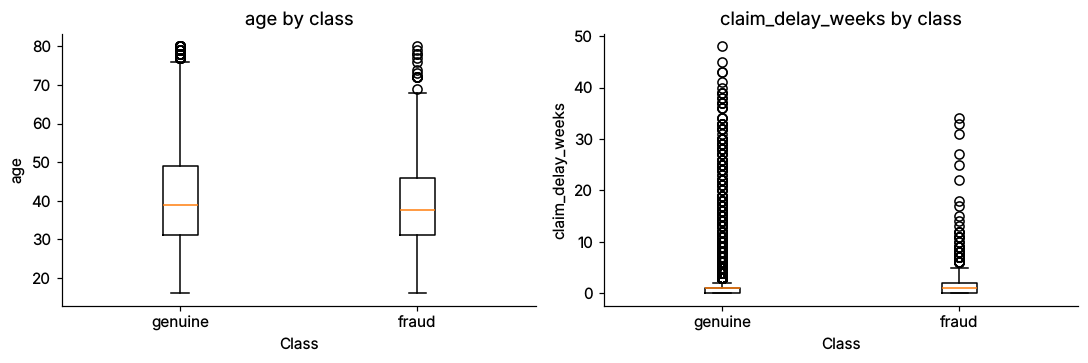

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, col in zip(axes, ["age", "claim_delay_weeks"]):
    ax.boxplot([X_train.loc[y_train == 0, col].dropna(), X_train.loc[y_train == 1, col].dropna()], tick_labels=["genuine", "fraud"])
    ax.set_title(f"{col} by class"); ax.set_ylabel(col); ax.set_xlabel("Class")
plt.tight_layout(); plt.savefig(FIG / "outliers.png", dpi=150); plt.show()

**Decision: keep all outliers.**
* **age:** values of 66–80 are flagged by the IQR rule but are real drivers.
* **claim_delay_weeks:** long delays are rare but genuine, and late reporting is a known fraud red flag, so removing them would remove signal.
* **deductible:** 96% of policies have 400, so the IQR is 0 and *every* other value (300/500/700) looks like an "outlier". These are real policy options, not errors.

None of these are data-entry errors, so nothing is deleted. Tree models are insensitive to extreme values, and for logistic regression the scaler handles the range.

### 4.6 Scaling
* **Logistic regression:** `StandardScaler` on numeric and ordinal columns (fitted on train). It is trained by gradient descent with an L2 penalty, so unscaled `deductible` (300–700) would dominate `driver_rating` (1–4).
* **Random forest / gradient boosting:** no scaling, since tree splits don't depend on feature scale.
* **Log transform:** not needed. The only skewed column, `claim_delay_weeks`, is a small integer (0–48) and trees handle skew natively.

All of this is in `features.build_preprocessor(scale=...)`, a `ColumnTransformer` that sits **inside** the model `Pipeline`. So it is fitted on training folds only, and exactly the same steps run inside the API.

In [16]:
prep = build_preprocessor(scale=True).fit(X_train)
Xt = prep.transform(X_train)
print("Columns after preprocessing:", Xt.shape[1])
print(list(prep.get_feature_names_out()))

Columns after preprocessing: 41
['age', 'deductible', 'driver_rating', 'claim_delay_weeks', 'missingindicator_age', 'sex', 'fault', 'accident_area', 'police_report_filed', 'witness_present', 'agent_type', 'vehicle_price', 'age_of_vehicle', 'past_number_of_claims', 'number_of_supplements', 'address_change_claim', 'number_of_cars', 'days_policy_accident', 'marital_status_Single', 'marital_status_Married', 'marital_status_Divorced', 'marital_status_Widow', 'base_policy_Liability', 'base_policy_Collision', 'base_policy_All Perils', 'vehicle_category_Sedan', 'vehicle_category_Sport', 'vehicle_category_Utility', 'make_Pontiac', 'make_Toyota', 'make_Honda', 'make_Mazda', 'make_Chevrolet', 'make_Acura', 'make_Ford', 'make_VW', 'make_Dodge', 'make_Saab', 'make_Mercury', 'make_Saturn', 'make_Other']


## 5. Model comparison

We compare three algorithms with **5-fold stratified cross-validation on the training set**, then score the untouched test set once.

In [17]:
models = {
    "Logistic Regression": Pipeline([("prep", build_preprocessor(scale=True)),
                                     ("clf", LogisticRegression(class_weight="balanced", max_iter=5000, random_state=SEED))]),
    "Random Forest": Pipeline([("prep", build_preprocessor(scale=False)),
                               ("clf", RandomForestClassifier(n_estimators=300, max_depth=6, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED))]),
    "Gradient Boosting (HGB)": Pipeline([("prep", build_preprocessor(scale=False)),
                                         ("clf", HistGradientBoostingClassifier(learning_rate=0.05, max_iter=400, max_depth=6, min_samples_leaf=20, class_weight="balanced", random_state=SEED))]),
}
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
rows = []
for name, pipe in models.items():
    s = cross_validate(pipe, X_train, y_train, cv=cv, scoring=["roc_auc", "average_precision", "recall", "f1"])
    rows.append({"model": name, "CV ROC-AUC": s["test_roc_auc"].mean(), "± std": s["test_roc_auc"].std(),
                 "CV PR-AUC": s["test_average_precision"].mean(), "CV recall@0.5": s["test_recall"].mean(), "CV F1@0.5": s["test_f1"].mean()})
cv_results = pd.DataFrame(rows).set_index("model").round(4)
cv_results

,CV ROC-AUC,± std,CV PR-AUC,CV recall@0.5,CV F1@0.5
model,,,,,
Logistic Regression,0.7899,0.0088,0.1544,0.8672,0.2151
Random Forest,0.8041,0.0051,0.1812,0.9404,0.2252
Gradient Boosting (HGB),0.7969,0.0119,0.2170,0.5420,0.2332


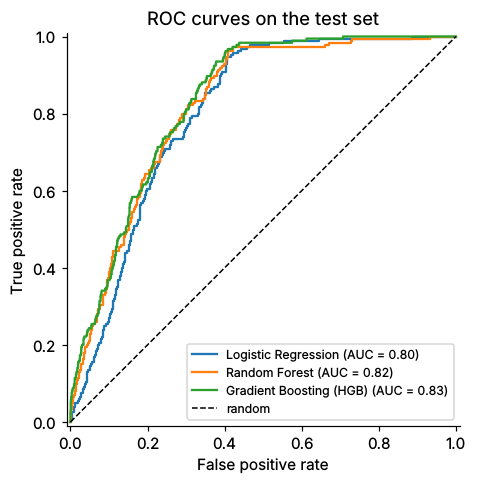

,test ROC-AUC,test PR-AUC
model,,
Logistic Regression,0.8043,0.1509
Random Forest,0.8215,0.2001
Gradient Boosting (HGB),0.8327,0.2459


In [18]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
test_rows = []
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    proba = pipe.predict_proba(X_test)[:, 1]
    RocCurveDisplay.from_predictions(y_test, proba, name=name, ax=ax)
    test_rows.append({"model": name, "test ROC-AUC": roc_auc_score(y_test, proba), "test PR-AUC": average_precision_score(y_test, proba)})
ax.plot([0, 1], [0, 1], "k--", lw=1, label="random"); ax.set_title("ROC curves on the test set")
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "roc_curves.png", dpi=150); plt.show()
pd.DataFrame(test_rows).set_index("model").round(4)

### 5.1 Choosing the decision threshold
With 6% fraud, a cut-off of 0.5 isn't automatically right. Following `train.py`, we split a validation slice off the **training** data, pick the threshold that maximises F1 there, and then report test results at that threshold.

Tuned threshold: 0.578
Test  recall 0.832 | precision 0.145 | F1 0.247


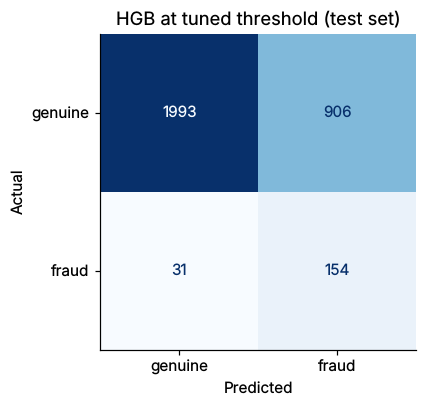

In [19]:
best = models["Gradient Boosting (HGB)"]
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.25, stratify=y_train, random_state=SEED)
best.fit(X_fit, y_fit)
prec, rec, thr = precision_recall_curve(y_val, best.predict_proba(X_val)[:, 1])
f1 = 2 * prec * rec / np.clip(prec + rec, 1e-9, None)
threshold = thr[np.argmax(f1[:-1])]
best.fit(X_train, y_train)
proba = best.predict_proba(X_test)[:, 1]; pred = (proba >= threshold).astype(int)
print(f"Tuned threshold: {threshold:.3f}")
print(f"Test  recall {recall_score(y_test, pred):.3f} | precision {precision_score(y_test, pred):.3f} | F1 {f1_score(y_test, pred):.3f}")
fig, ax = plt.subplots(figsize=(4.4, 3.8))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["genuine", "fraud"], cmap="Blues", colorbar=False, ax=ax)
ax.set_title("HGB at tuned threshold (test set)"); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.savefig(FIG / "confusion_matrix.png", dpi=150); plt.show()

## 6. What drives the model (permutation importance on the test set)

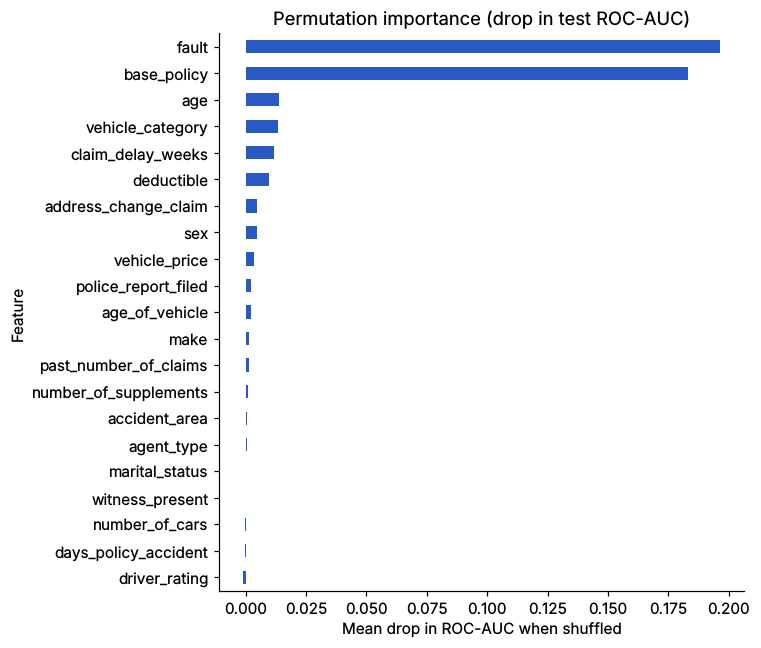

In [20]:
pi = permutation_importance(best, X_test, y_test, scoring="roc_auc", n_repeats=5, random_state=SEED, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values()
ax = imp.plot.barh(figsize=(7, 6), color="#2b59c3")
ax.set_title("Permutation importance (drop in test ROC-AUC)"); ax.set_xlabel("Mean drop in ROC-AUC when shuffled"); ax.set_ylabel("Feature")
plt.tight_layout(); plt.savefig(FIG / "permutation_importance.png", dpi=150); plt.show()

**Reading it.** `fault` and `base_policy` dominate, which matches the EDA: fraud needs a policy that pays out for the holder's own car. Age, vehicle category, claim delay, deductible and address changes add smaller signals. Days from policy start shows a strong pattern in the EDA, but it affects so few claims (less than 2%) that shuffling it barely moves the test score. Features near zero are candidates to drop in a future version.

## 7. Conclusions
* **Chosen model: HistGradientBoosting.** It has the best **PR-AUC** in cross-validation and on the test set, plus the best test ROC-AUC. Random forest's CV ROC-AUC is slightly higher, but within one standard deviation. With only 6% fraud, PR-AUC is the metric that reflects how well we rank the rare fraud cases, so it decides. Logistic regression is a solid, explainable baseline but cannot capture interactions such as "at fault **and** all-perils policy". Random forest sits in between. The MLflow runs from `train.py` confirm this ranking (see the README table).
* **Imbalance is the core difficulty.** PR-AUC of about 0.25 is roughly 4 times better than random (0.06). The tuned model catches most frauds, at the cost of flagging some genuine claims for review. That trade-off is acceptable for a **triage** tool, where a human investigator makes the final call.
* **Limitations:** this is old (1994–96), US-only sample data. Many inputs arrive pre-binned, which limits precision, and there are only about 900 fraud examples.

## References
1. Vehicle Insurance Claim Fraud Detection dataset (`fraud_oracle.csv`), Oracle sample data, published by Shivam Bansal on Kaggle: https://www.kaggle.com/datasets/shivamb/vehicle-claim-fraud-detection. Used for: the dataset. Our copy was downloaded from a public GitHub mirror: https://github.com/abhisheks008/Car.ly
2. scikit-learn documentation, https://scikit-learn.org. Used for: preprocessing, models and metrics.
3. An AI assistant (Claude) helped draft code and explanations. The team reviewed every step and can explain it.